# MLP Neural Network: baseline and tuned classifier
**Review 2 · Classification Part B · target: transmission**

Predict Automatic vs Manual using 2,500 distinct real UK listing records (1,250 per class).
Prices are GBP and distance is miles. Source records come from Aditya Desai's UK used-car dataset;
no synthetic or repeated training rows are added. Distinct rows do not establish VIN-level uniqueness.

The fixed 80:20 stratified split gives 2,000 training rows and 500 test rows, with equal classes in both.
**No oversampling or class weights are needed.** Fit imputation, scaling and encoding inside each fold.
All Part A and B reruns share this new dataset and split; these are not the original Review 1 scores.
The balanced test sample measures performance for this sampled population, not natural market prevalence.

Selection uses **five-fold macro F1**, which gives both classes equal importance. Required weighted
metrics are also reported. The test set is used for the final before/after comparison, never to choose parameters.
The same feature engineering, preprocessing are used before and after tuning.


In [1]:
from pathlib import Path
import sys, os, warnings, json
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if not (ROOT / 'src').exists():
    raise RuntimeError('Open this notebook inside the extracted project/notebooks folder.')
sys.path.insert(0, str(ROOT))
from threadpoolctl import threadpool_limits
thread_limit = threadpool_limits(limits=1)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
%matplotlib inline
sns.set_theme(style='whitegrid', palette='colorblind')
from sklearn.base import clone
from sklearn.model_selection import cross_validate, GridSearchCV
from src.classification import *
raw, df, train, test = load_data()
X_train, y_train = train[RAW_FEATURES], train[TARGET]
X_test, y_test = test[RAW_FEATURES], test[TARGET]
display(pd.DataFrame({'Raw': raw[TARGET].value_counts(), 'Cleaned': df[TARGET].value_counts(),
                      'Train': y_train.value_counts(), 'Test': y_test.value_counts()}))
display(df.dtypes.to_frame('dtype').astype(str))
print('Removed exact duplicate rows:', len(raw) - len(df))
assert not df.duplicated().any()
assert set(train.index).isdisjoint(test.index)


Removed exact duplicate rows: 0


,Raw,Cleaned,Train,Test
transmission,,,,
Automatic,1250,1250,1000,250
Manual,1250,1250,1000,250


,dtype
brand,object
model,object
year,int64
price_gbp,int64
mileage_miles,int64
fuel_type,object
tax_gbp,int64
mpg_uk,float64
engine_size_l,float64
transmission,string


## Training-data audit and EDA
Missing numeric/categorical values, if present, are imputed within each training fold.
Car age uses a fixed reference year (2026); log price/log miles reduce positive skew. Brand, model,
fuel, tax, MPG and engine displacement remain available to the classifier. IQR outliers
are reported and retained rather than deleting legitimate expensive or high-mileage cars.

**Team task:** write your own observations from each plot and justify these feature choices, as required by the guidelines.


Cleaned shape: (2500, 10) | Training: 2000 | Test: 500
Missing training values:
 brand            0
model            0
year             0
price_gbp        0
mileage_miles    0
fuel_type        0
tax_gbp          0
mpg_uk           0
engine_size_l    0
transmission     0
Training IQR outlier counts (retained; log transforms reduce skew):
car_age           38
log_price         22
log_mileage       74
tax_gbp          642
mpg_uk            20
engine_size_l    147


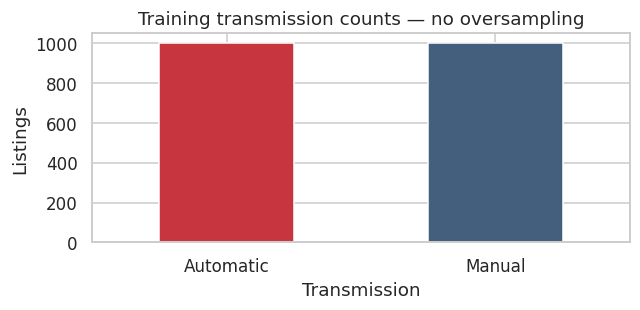

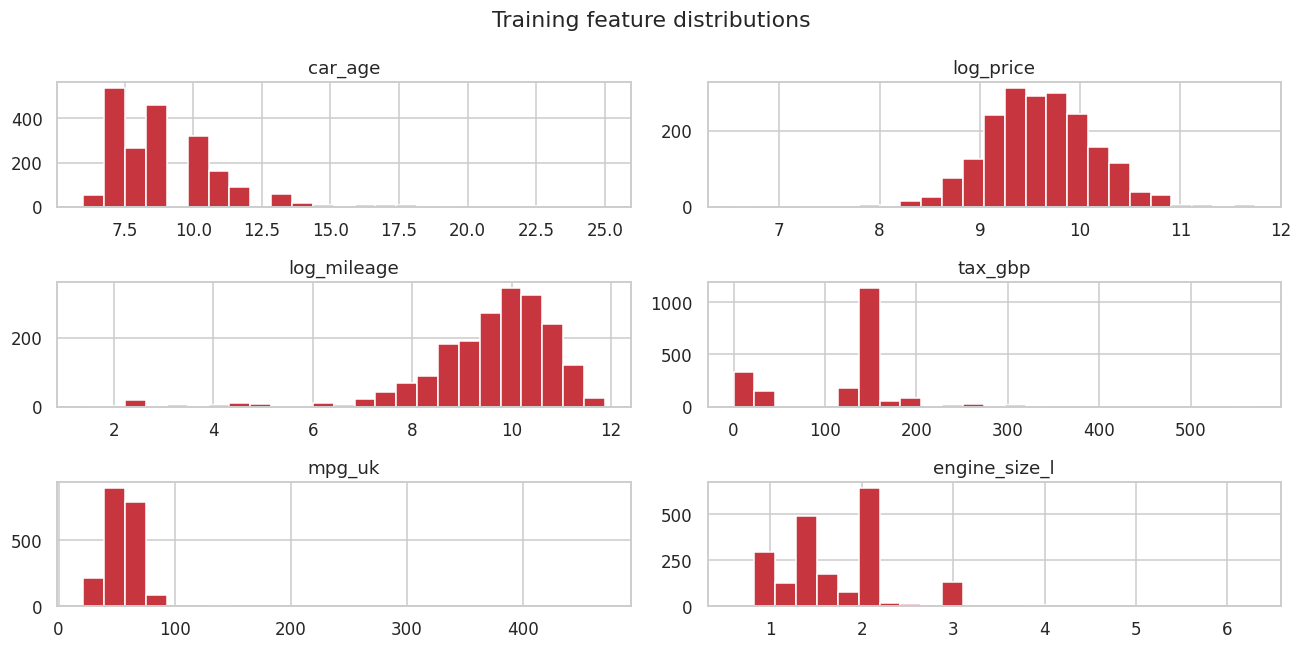

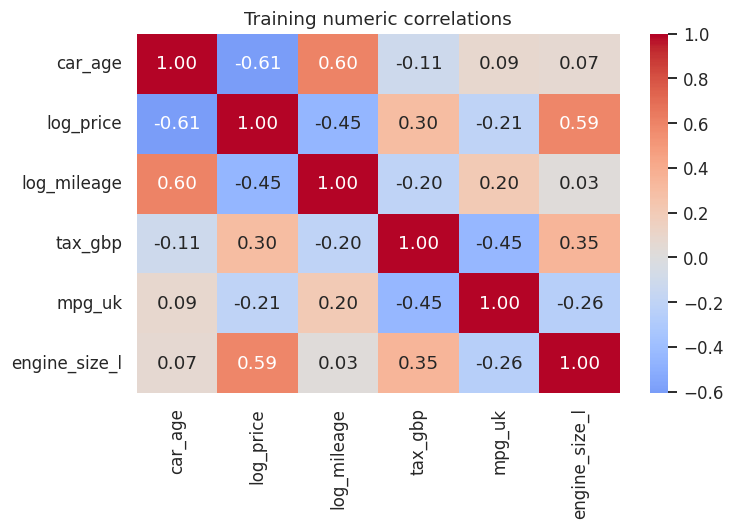

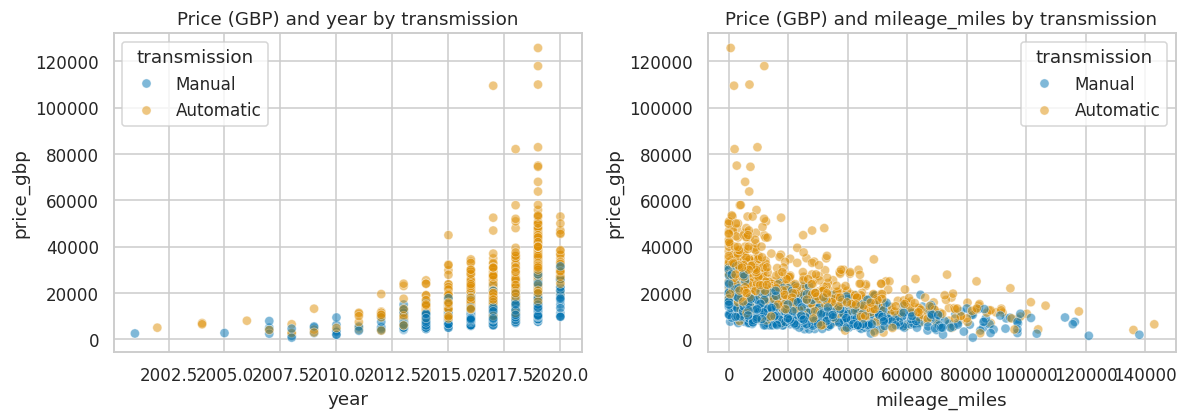

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
brand,2000,9,Ford,312,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,2000,143,Fiesta,118,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,2000.0,NaN,NaN,NaN,2016.9735,2.129569,2001.0,2016.0,2017.0,2019.0,2020.0
price_gbp,2000.0,NaN,NaN,NaN,17001.7955,10392.673128,694.0,10417.25,14492.0,20900.0,125796.0
mileage_miles,2000.0,NaN,NaN,NaN,24529.251,21740.610165,3.0,8121.75,18820.0,34000.0,143000.0
fuel_type,2000,4,Petrol,1001,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tax_gbp,2000.0,NaN,NaN,NaN,120.4075,67.327468,0.0,125.0,145.0,145.0,570.0
mpg_uk,2000.0,NaN,NaN,NaN,55.725,17.138348,21.4,46.3,55.4,63.15,470.8
engine_size_l,2000.0,NaN,NaN,NaN,1.7235,0.577472,0.6,1.4,1.6,2.0,6.3
transmission,2000,2,Manual,1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


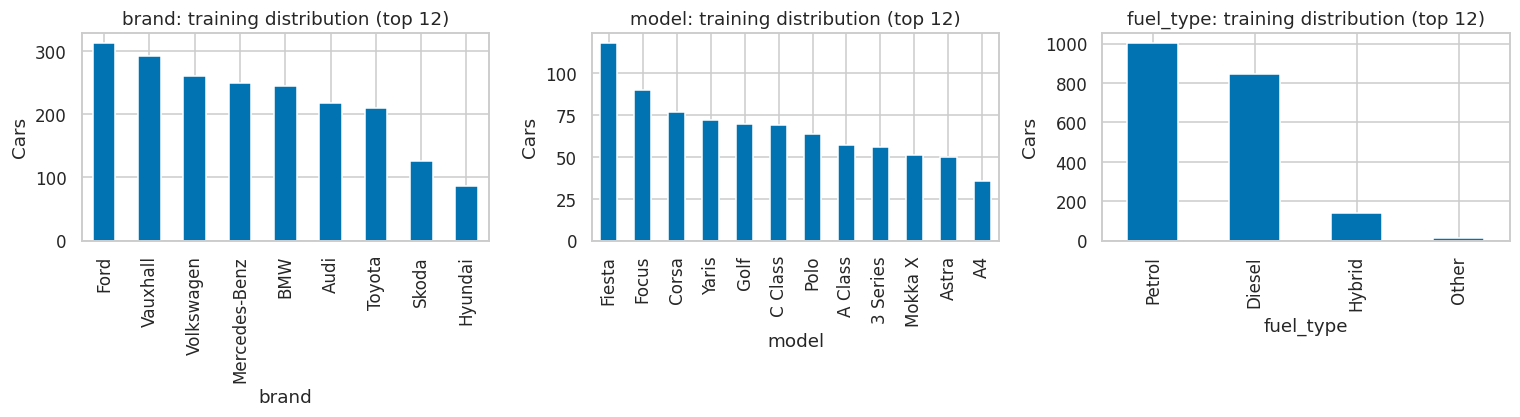

In [2]:
audit_plots(df, train)
display(train.describe(include='all').T)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
features = CarFeatures().transform(X_train)
for ax, col in zip(axes.ravel(), ['brand', 'model', 'fuel_type']):
    features[col].value_counts().head(12).plot.bar(ax=ax)
    ax.set(title=f'{col}: training distribution (top 12)', xlabel=col, ylabel='Cars')
plt.tight_layout(); plt.show()


## Model and search space
The displayed estimator is the untuned baseline. The search includes its parameter settings. A tied or lower test score after tuning is reported honestly.

In [3]:
slug = 'mlp'
name, estimator, parameter_grid = configurations()[slug]
display(estimator)
display(parameter_grid)
baseline = build_pipeline(clone(estimator))
warning_messages = []


,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(100,)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",800
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary `.",42


[{'model__hidden_layer_sizes': [(100,)],
  'model__activation': ['relu'],
  'model__alpha': [0.0001]},
 {'model__hidden_layer_sizes': [(50,), (64, 32)],
  'model__activation': ['relu', 'tanh'],
  'model__alpha': [0.01]}]

## Before tuning: five-fold CV and full training fit

In [4]:
with warnings.catch_warnings(record=True) as captured:
    warnings.simplefilter('always')
    baseline_cv = cross_validate(baseline, X_train, y_train, cv=CV, scoring=SCORING,
                                 n_jobs=1, error_score='raise')
    baseline.fit(X_train, y_train)
warning_messages.extend(str(w.message) for w in captured)
display(pd.DataFrame({k: v for k, v in baseline_cv.items() if k.startswith('test_')}))
print('Mean baseline macro F1:', baseline_cv['test_f1_macro'].mean())


Mean baseline macro F1: 0.8449417550230475


,test_f1_macro,test_f1_weighted,test_balanced_accuracy
0,0.872493,0.872493,0.8725
1,0.842491,0.842491,0.8425
2,0.824842,0.824842,0.8250
3,0.857392,0.857392,0.8575
4,0.827490,0.827490,0.8275


## After tuning: GridSearchCV
Imputation, encoding and scaling are refitted independently inside each fold. The MLP uses a fixed convergence budget without internal early stopping; no test rows are used while fitting.

In [5]:
search = GridSearchCV(build_pipeline(clone(estimator)), parameter_grid,
                      scoring=SCORING, refit='f1_macro', cv=CV,
                      n_jobs=1, error_score='raise', return_train_score=False)
with warnings.catch_warnings(record=True) as captured:
    warnings.simplefilter('always')
    search.fit(X_train, y_train)
warning_messages.extend(str(w.message) for w in captured)
tuned = search.best_estimator_
print('Best parameters:', search.best_params_)
print('Best training CV macro F1:', search.best_score_)
display(pd.DataFrame(search.cv_results_)[['params', 'mean_test_f1_macro',
    'std_test_f1_macro', 'mean_test_f1_weighted', 'rank_test_f1_macro']].sort_values('rank_test_f1_macro'))
print('Recorded training warnings:', sorted(set(warning_messages)) or 'None')


Best parameters: {'model__activation': 'relu', 'model__alpha': 0.0001, 'model__hidden_layer_sizes': (100,)}
Best training CV macro F1: 0.8449417550230475
Recorded training warnings: None


,params,mean_test_f1_macro,std_test_f1_macro,mean_test_f1_weighted,rank_test_f1_macro
0,"{'model__activation': 'relu', 'model__alpha': ...",0.844942,0.018048,0.844942,1
1,"{'model__activation': 'relu', 'model__alpha': ...",0.837343,0.023574,0.837343,2
3,"{'model__activation': 'tanh', 'model__alpha': ...",0.834807,0.026801,0.834807,3
4,"{'model__activation': 'tanh', 'model__alpha': ...",0.834434,0.010690,0.834434,4
2,"{'model__activation': 'relu', 'model__alpha': ...",0.827905,0.015596,0.827905,5


## Held-out test comparison
ROC-AUC and average precision consistently treat **Automatic as positive**. Weighted recall equals accuracy in this single-label task. CV scores used for tuning are selection estimates, not independent generalization estimates.

,Model,Stage,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,F1_macro,Balanced_accuracy,Automatic_precision,Automatic_recall,ROC_AUC,Average_precision_Automatic,CV_macro_F1,CV_macro_F1_std
0,MLP,Before tuning,0.846,0.8469,0.846,0.8459,0.8459,0.846,0.865,0.82,0.9273,0.9344,0.8449,0.018
1,MLP,After tuning,0.846,0.8469,0.846,0.8459,0.8459,0.846,0.865,0.82,0.9273,0.9344,0.8449,0.018


,After minus before
Accuracy,0.0
F1_weighted,0.0
F1_macro,0.0
Automatic_recall,0.0
ROC_AUC,0.0
CV_macro_F1,0.0


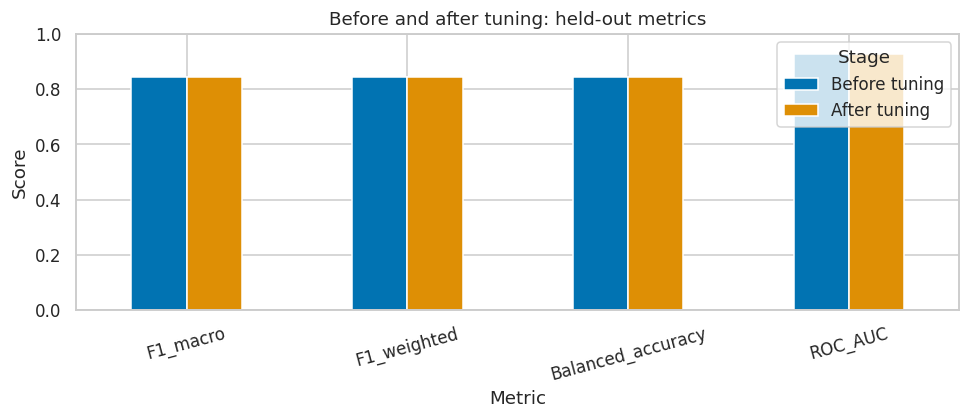

,precision,recall,f1-score,support
Automatic,0.864979,0.820,0.841889,250.000
Manual,0.828897,0.872,0.849903,250.000
accuracy,0.846000,0.846,0.846000,0.846
macro avg,0.846938,0.846,0.845896,500.000
weighted avg,0.846938,0.846,0.845896,500.000


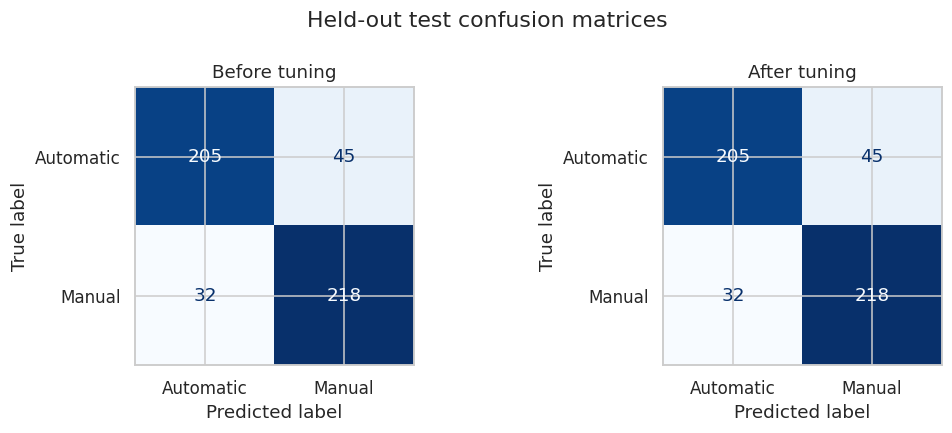

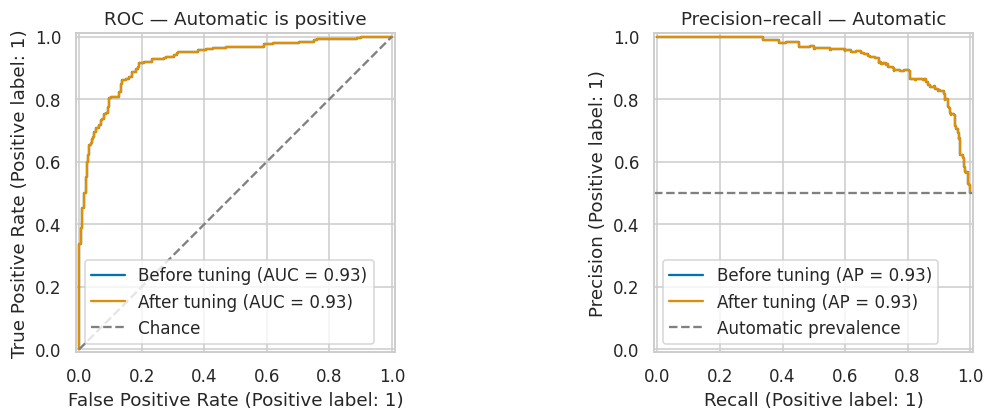

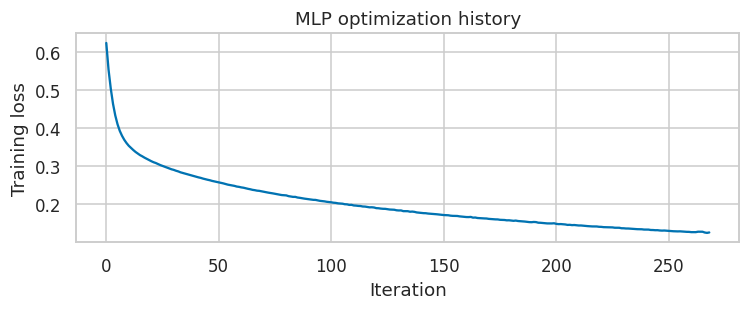

In [6]:
comparison = evaluate_pair(slug, name, baseline, tuned, X_test, y_test,
                           baseline_cv, search, warning_messages)
display(comparison.round(4))
metric_cols = ['Accuracy', 'F1_weighted', 'F1_macro', 'Automatic_recall', 'ROC_AUC', 'CV_macro_F1']
delta = comparison.loc[1, metric_cols] - comparison.loc[0, metric_cols]
display(delta.to_frame('After minus before'))
comparison.set_index('Stage')[['F1_macro', 'F1_weighted', 'Balanced_accuracy', 'ROC_AUC']].T.plot.bar(figsize=(9, 4), ylim=(0, 1))
plt.title('Before and after tuning: held-out metrics'); plt.xlabel('Metric'); plt.ylabel('Score')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()
display(pd.read_csv(ROOT / 'results' / slug / 'after_class_report.csv', index_col=0))
plot_pair(slug, baseline, tuned, X_test, y_test)


## Team interpretation and viva preparation
Complete these prompts yourself after inspecting the actual outputs:
- Which metric changed most, and by how much? Did test performance improve or decline?
- How many Automatic cars were missed before and after tuning?
- Why is oversampling unnecessary here? What does distinct listing data establish, and what does it not prove?
- Explain this model's training mechanism and the selected hyperparameters.
- Why might CV improvement fail to produce test improvement?

Models and numeric results are exported to `models/` and `results/`. The GUI reads those same files.
Source: [scikit-learn](https://scikit-learn.org/stable/). See data/CLASSIFICATION_DATA_SOURCE.md for dataset provenance.
AI-assisted code scaffolding is disclosed in README. Your interpretation must be original.
